In [1]:
# conda env 'vis2'

import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

from util import load_sensor_dict
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import glob
import at3d

In [2]:
version_dir = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/V03'
data = {}
data['obs'] = {'files': ['/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc']}
data['0.1'] = {'files': np.sort(glob.glob(version_dir + '/surf_wind/0p1/iterations/iter*.nc'))}
data['0.67'] = {'files': np.sort(glob.glob(version_dir + '/default/iterations/iter*.nc'))}
data['1.33'] = {'files': np.sort(glob.glob(version_dir + '/surf_wind/1p33/iterations/iter*.nc'))}

CVM_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/CVM_default_open.nc'

In [3]:
for k in data:
    try:
        sensors, solvers, rte_grid = at3d.util.load_forward_model(data[k]['files'][-1])
        data[k]['sensors'] = sensors
        data[k]['solvers'] = solvers
        data[k]['rte_grid'] = rte_grid
        data[k]['cloud'] = solvers[0.67].medium['cloud']
        data[k]['sl'] = sensors['MISR']['sensor_list']
    except:
        sensors = load_sensor_dict(data[k]['files'][-1])
        solvers = None
        rte_grid = None
        data[k]['sensors'] = sensors
        data[k]['sl'] = sensors['MISR']['sensor_list']
    del sensors, solvers, rte_grid

cvm = xr.load_dataset(CVM_file)

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '41'. Max cell optical depth: '3.140909194946289'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.

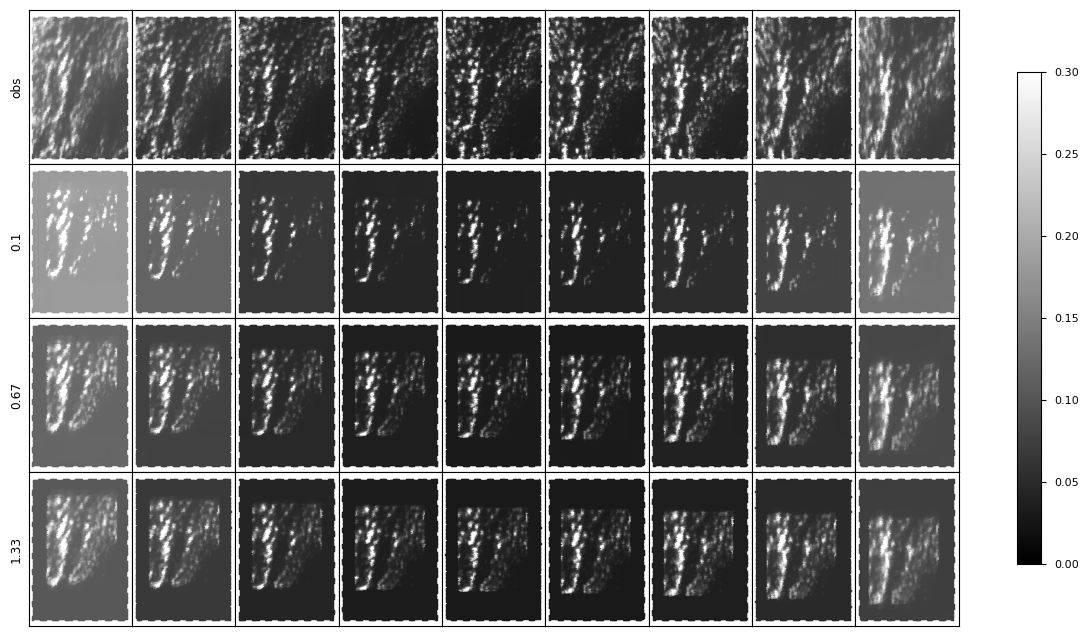

In [4]:
s = 2
vmin = 0
vmax = 0.3

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, cam in enumerate(data[k]['sl']):
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.I.data*np.pi/cam.mu0, marker='s', cmap='gray', vmin=vmin, vmax=vmax)
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel(k)
plt.colorbar(scat, ax=ax[:], shrink=0.8)

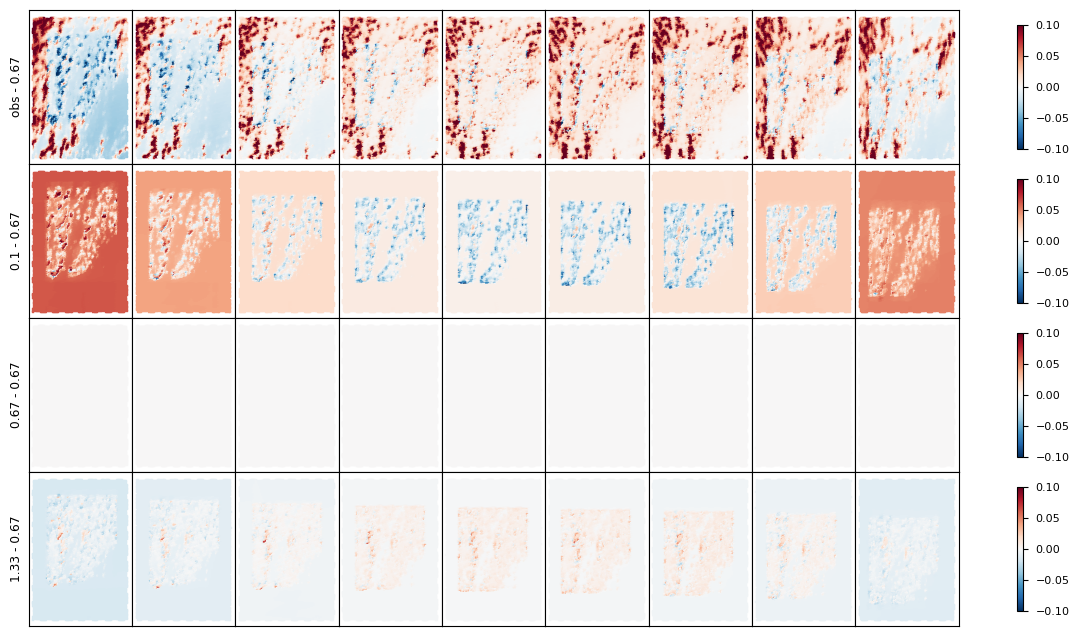

In [5]:
s = 2
vrange = [0.1, 0.1, 0.1, 0.1]

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, (cam, defcam) in enumerate(zip(data[k]['sl'], data['0.67']['sl'])):
        I = (cam.I.data*np.pi/cam.mu0) - (defcam.I.data*np.pi/defcam.mu0)
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=I, marker='s', cmap='RdBu_r', vmin=-vrange[i], vmax=vrange[i])
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel('{} - 0.67'.format(k))
    plt.colorbar(scat, ax=ax[i, :], shrink=0.8)

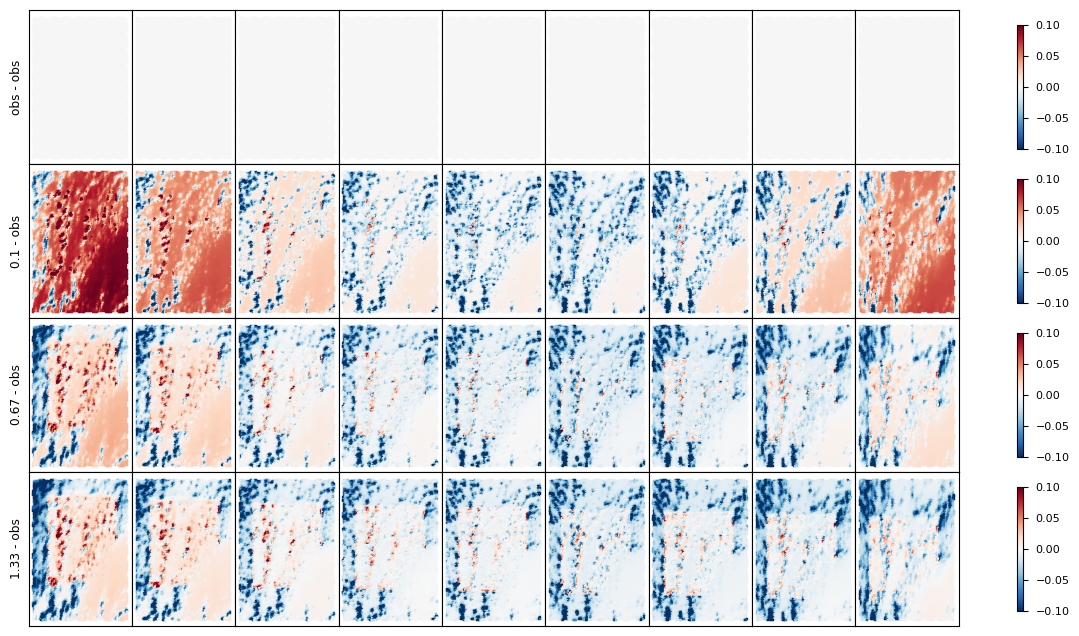

In [6]:
s = 2
vrange = [0.1, 0.1, 0.1, 0.1]

plt.style.use('seaborn-v0_8-paper')
n = len(list(data.keys()))
f, ax = plt.subplots(n, 9, figsize=(15,2*n))
plt.subplots_adjust(wspace=0, hspace=0)
for i, k in enumerate(data):
    for j, (cam, defcam) in enumerate(zip(data[k]['sl'], data['obs']['sl'])):
        I = (cam.I.data*np.pi/cam.mu0) - (defcam.I.data*np.pi/defcam.mu0)
        scat = ax[i, j].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=I, marker='s', cmap='RdBu_r', vmin=-vrange[i], vmax=vrange[i])
        ax[i, j].set_xlim([-4, 22])
        ax[i, j].set_ylim([-7, 25])
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
    ax[i, 0].set_ylabel('{} - obs'.format(k))
    plt.colorbar(scat, ax=ax[i, :], shrink=0.8)

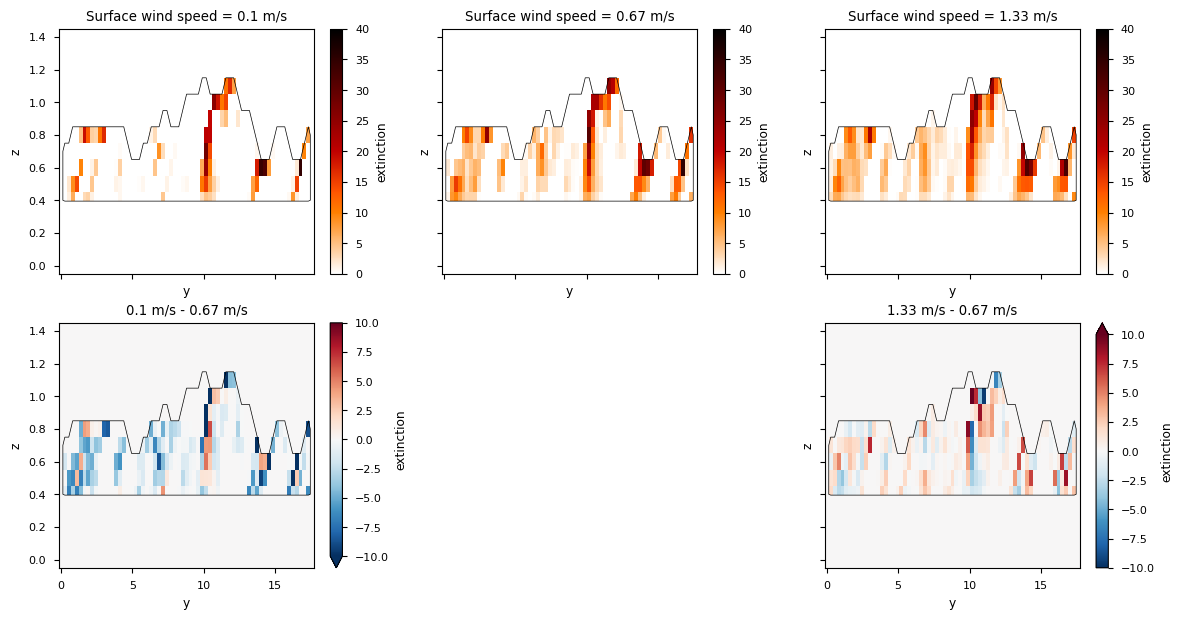

In [8]:
ext_cmap = 'gist_heat_r'
x = 3.3
vmax = 40
vrange = 10
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(2, 3, figsize=(14, 7), sharey=True, sharex=True)
data['0.1']['cloud'].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[0, 0], vmin=0, vmax=vmax, cmap=ext_cmap)
data['0.67']['cloud'].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[0, 1], vmin=0, vmax=vmax, cmap=ext_cmap)
data['1.33']['cloud'].sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[0, 2], vmin=0, vmax=vmax, cmap=ext_cmap)
(data['0.1']['cloud'].extinction - data['0.67']['cloud'].extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[1, 0], vmin=-vrange, vmax=vrange, cmap='RdBu_r')
(data['1.33']['cloud'].extinction - data['0.67']['cloud'].extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[1, 2], vmin=-vrange, vmax=vrange, cmap='RdBu_r')
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0, 0], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0, 1], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0, 2], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[1, 0], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[1, 2], colors='black', linewidths=0.5)

ax[0, 0].set_title('Surface wind speed = 0.1 m/s')
ax[0, 1].set_title('Surface wind speed = 0.67 m/s')
ax[0, 2].set_title('Surface wind speed = 1.33 m/s')
ax[1, 0].set_title('0.1 m/s - 0.67 m/s')
ax[1, 2].set_title('1.33 m/s - 0.67 m/s')
ax[1, 1].set_axis_off()
